<a href="https://colab.research.google.com/github/hbhoomikacs24-stack/lab-programs-for-AI/blob/main/week8_1BM24CS107_forward_chaining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     UNIVERSAL FIRST-ORDER LOGIC INFERENCE ENGINE    

--- Step 1: Input Knowledge Base Facts ---
Facts: American(West), Owns(Nono,M1), Missile(M1), Enemy(Nono,America)

--- Step 2: Input Rules Base Rules ---
Rule 1: Missile(x) -> Weapon(x)
Rule 2: Missile(x) & Owns(Nono,x) -> Sells(West,x,Nono)
Rule 3: Enemy(x,America) -> Hostile(x)
Rule 4: American(x) & Weapon(y) & Sells(x,y,z) & Hostile(z) -> Criminal(x)
Rule 5: DONE

--- Step 3: Input Target Goal Query ---
Target Goal: Criminal(West)

--- [Inference Progress Log] ---
Iteration 1: Derived -> Weapon(M1)
Iteration 1: Derived -> Sells(West, M1, Nono)
Iteration 1: Derived -> Hostile(Nono)
Iteration 2: Derived -> Criminal(West)

Final Engine Goal Outcome Check: PROVEN SUCCESSFUL


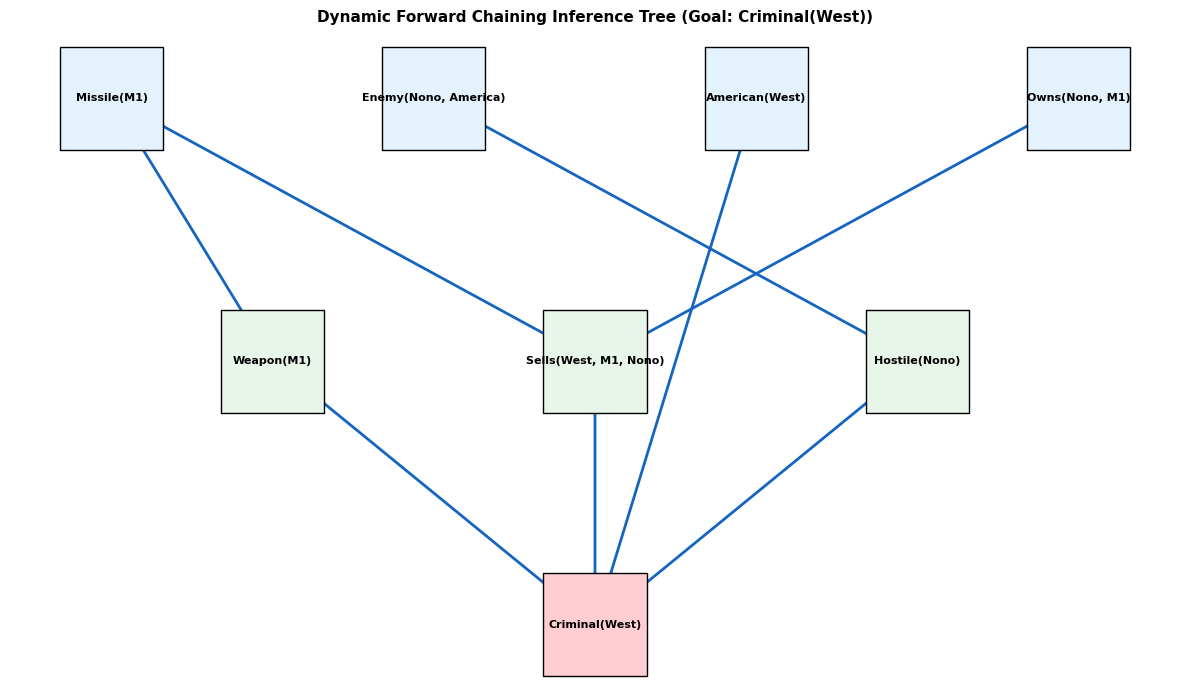

In [9]:
import matplotlib.pyplot as plt
import networkx as nx
import re

class Fact:
    def __init__(self, predicate, arguments):
        self.predicate = predicate
        self.arguments = tuple(arg.strip() for arg in arguments)

    def __repr__(self):
        return f"{self.predicate}({', '.join(self.arguments)})"

    def __eq__(self, other):
        return isinstance(other, Fact) and self.predicate == other.predicate and self.arguments == other.arguments

    def __hash__(self):
        return hash((self.predicate, self.arguments))

class Rule:
    def __init__(self, antecedents, consequent):
        self.antecedents = antecedents
        self.consequent = consequent

    def __repr__(self):
        antecedents_str = " ∧ ".join([f"{p}({', '.join(a)})" for p, a in self.antecedents])
        return f"{antecedents_str} ⇒ {self.consequent}({', '.join(self.consequent)})"

def unify(rule_args, fact_args, theta):
    if theta is None: return None
    if len(rule_args) != len(fact_args): return None
    new_theta = theta.copy()
    for r_arg, f_arg in zip(rule_args, fact_args):
        if r_arg.islower():
            if r_arg in new_theta:
                if new_theta[r_arg] != f_arg: return None
            else:
                new_theta[r_arg] = f_arg
        else:
            if r_arg != f_arg: return None
    return new_theta

def substitute(theta, element):
    pred, args = element
    new_args = tuple(theta.get(arg, arg) for arg in args)
    return Fact(pred, new_args)

def clean_prefix(text):
    text = text.strip()
    # Remove colon headers like 'Rule 1:'
    text = re.sub(r'^.*?:\s*', '', text)
    # BULLETPROOF FIX: Automatically strip out numbers like '3.', '5.', 'Rule 3' from the beginning of the text
    text = re.sub(r'^(?:\d+\.|\bRule\s*\d+\.?)\s*', '', text, flags=re.IGNORECASE)
    return text.strip()

def parse_fact_string(text):
    text = clean_prefix(text)
    if not text or "(" not in text or not text.endswith(")"): return None
    idx = text.index("(")
    predicate = text[:idx].strip()
    args_str = text[idx+1:-1]
    arguments = tuple(arg.strip() for arg in args_str.split(",") if arg.strip())
    return Fact(predicate, arguments)

def parse_rule_string(text):
    text = clean_prefix(text)
    if "->" not in text and "=>" not in text: return None
    normalized_text = text.replace("=>", "->")
    left, right = normalized_text.split("->")
    consequent_fact = parse_fact_string(right)
    if not consequent_fact: return None

    parts = re.split(r'\s*(?:&|\^|\bAND\b)\s*', left)
    antecedents = []
    for part in parts:
        f = parse_fact_string(part)
        if f:
            antecedents.append((f.predicate, f.arguments))
    if antecedents:
        return Rule(antecedents, (consequent_fact.predicate, consequent_fact.arguments))
    return None

def standardize_variables(rule, index):
    var_map = {}
    new_antecedents = []
    for pred, args in rule.antecedents:
        new_args = []
        for arg in args:
            if arg.islower():
                if arg not in var_map:
                    var_map[arg] = f"{arg}_{index}"
                new_args.append(var_map[arg])
            else:
                new_args.append(arg)
        new_antecedents.append((pred, tuple(new_args)))

    conseq_pred, conseq_args = rule.consequent
    new_conseq_args = []
    for arg in conseq_args:
        if arg.islower():
            if arg not in var_map:
                var_map[arg] = f"{arg}_{index}"
            new_conseq_args.append(var_map[arg])
        else:
            new_conseq_args.append(arg)

    return Rule(new_antecedents, (conseq_pred, tuple(new_conseq_args)))

def fol_fc_ask_universal(KB_rules, KB_facts, alpha):
    standardized_rules = [standardize_variables(r, i) for i, r in enumerate(KB_rules)]
    known_facts = set(KB_facts)
    edges = []
    node_layers = {str(f): 0 for f in known_facts}

    print("\n--- [Inference Progress Log] ---")
    iteration = 1
    goal_reached = False

    while not goal_reached:
        new_facts_this_iteration = set()
        for rule in standardized_rules:
            substitutions = [{'theta': {}, 'matched': []}]

            for ant_pred, ant_args in rule.antecedents:
                next_substitutions = []
                for sub_dict in substitutions:
                    current_theta = sub_dict['theta']
                    current_matched = sub_dict['matched']
                    for fact in known_facts:
                        if fact.predicate == ant_pred:
                            new_theta = unify(ant_args, fact.arguments, current_theta)
                            if new_theta is not None:
                                next_substitutions.append({
                                    'theta': new_theta,
                                    'matched': current_matched + [str(fact)]
                                })
                substitutions = next_substitutions

            for sub_dict in substitutions:
                theta = sub_dict['theta']
                matched_facts = sub_dict['matched']
                q_prime = substitute(theta, rule.consequent)

                if q_prime not in known_facts and q_prime not in new_facts_this_iteration:
                    new_facts_this_iteration.add(q_prime)
                    print(f"Iteration {iteration}: Derived -> {q_prime}")

                    max_parent_layer = 0
                    for src in matched_facts:
                        edges.append((src, str(q_prime)))
                        max_parent_layer = max(max_parent_layer, node_layers.get(src, 0))
                    node_layers[str(q_prime)] = max_parent_layer + 1

                    if q_prime == alpha:
                        goal_reached = True

        if not new_facts_this_iteration: break
        known_facts.update(new_facts_this_iteration)
        iteration += 1

    return edges, node_layers, goal_reached

# ====================================================
# LIVE CONSOLE ENVIRONMENT
# ====================================================
print("====================================================")
print("     UNIVERSAL FIRST-ORDER LOGIC INFERENCE ENGINE    ")
print("====================================================\n")

print("--- Step 1: Input Knowledge Base Facts ---")
facts_raw = input("Facts: ").strip()

print("\n--- Step 2: Input Rules Base Rules ---")
rules_list = []
while True:
    rule_raw = input(f"Rule {len(rules_list)+1}: ").strip()
    if rule_raw.upper() == "DONE": break
    r_obj = parse_rule_string(rule_raw)
    if r_obj:
        rules_list.append(r_obj)
    else:
        print("Formatting error! Syntax template: A(x) & B(y) -> C(x)")

print("\n--- Step 3: Input Target Goal Query ---")
goal_raw = input("Target Goal: ").strip()

fact_items = re.findall(r'[A-Za-z0-9_]+\([^)]+\)', facts_raw)
parsed_facts = [parse_fact_string(item) for item in fact_items if parse_fact_string(item)]
parsed_goal = parse_fact_string(goal_raw)

if not parsed_facts or not parsed_goal:
    print("\n[Error]: Input processing failed. Please verify syntax structures.")
else:
    edges, layers, is_proven = fol_fc_ask_universal(rules_list, parsed_facts, parsed_goal)
    print(f"\nFinal Engine Goal Outcome Check: {'PROVEN SUCCESSFUL' if is_proven else 'UNABLE TO PROVE'}")

    # ====================================================
    # COMPACT GRAPH GENERATOR BLOCK
    # ====================================================
    if edges:
        layers_dict = {}
        for node, lvl in layers.items():
            if lvl not in layers_dict: layers_dict[lvl] = []
            layers_dict[lvl].append(node)

        G = nx.DiGraph()
        G.add_edges_from(edges)
        pos = {}

        for lvl, nodes in layers_dict.items():
            count = len(nodes)
            for idx, node in enumerate(nodes):
                if node in G.nodes():
                    x_coord = (idx - (count - 1) / 2.0) * 3.5 if count > 1 else 0.0
                    y_coord = -lvl * 1.5
                    pos[node] = (x_coord, y_coord)

        color_map = []
        for node in G.nodes():
            if str(parsed_goal) in node: color_map.append('#ffcdd2')
            elif layers.get(node, 0) == 0: color_map.append('#e3f2fd')
            else: color_map.append('#e8f5e9')

        plt.figure(figsize=(12, 7))
        nx.draw_networkx_nodes(G, pos, node_size=5500, node_color=color_map, node_shape='s', edgecolors='black')
        nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=20, edge_color='#1565c0', width=2)
        nx.draw_networkx_labels(G, pos, font_size=8, font_weight='bold')
        plt.title(f"Dynamic Forward Chaining Inference Tree (Goal: {parsed_goal})", fontsize=11, fontweight='bold', pad=15)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
